## Introducción Sencilla al Proyecto de Verificación de Edad

Este proyecto busca ayudar a la cadena de supermercados Good Seed a asegurarse de que no venden alcohol a personas que no tienen la edad legal para comprarlo. Utilizaremos cámaras instaladas en las cajas para analizar automáticamente la edad de los clientes.

### Descripción del Proyecto
El objetivo principal es desarrollar un sistema que pueda estimar la edad de una persona a partir de una fotografía. Esto es crucial para cumplir con las leyes de venta de alcohol y evitar infracciones.

### Objetivo del Proyecto
El objetivo es construir un modelo de inteligencia artificial que pueda predecir la edad de un cliente a partir de una imagen de su rostro. Queremos que esta predicción sea lo más precisa posible para que el supermercado pueda tomar decisiones informadas sobre la venta de alcohol.

### Métricas de Evaluación
Para saber qué tan bien funciona nuestro modelo, usaremos métricas como el **Error Absoluto Medio (MAE)** y el **Error Cuadrático Medio (MSE)**. Estas métricas nos indicarán, en promedio, cuánto se desvía la edad predicha por nuestro modelo de la edad real del cliente. Un MAE bajo (idealmente no superior a 8, y si es menor de 7, sería excelente) significa que el modelo es muy preciso.

### Datos Disponibles
Contamos con un conjunto de datos que incluye miles de fotografías de personas y sus edades reales. Estas imágenes están organizadas en una carpeta `final_files`, y las edades correspondientes se encuentran en un archivo `labels.csv`. Para manejar este gran volumen de imágenes de manera eficiente, utilizaremos generadores de datos que cargan las imágenes por lotes, en lugar de cargarlas todas a la vez.

### Metodología
1.  **Análisis Exploratorio de Datos (EDA)**: Primero, examinaremos a fondo los datos para entender la distribución de las edades, identificar patrones y asegurarnos de que no haya valores faltantes o duplicados.
2.  **Preparación de Datos**: Las imágenes se procesarán y redimensionarán para que sean compatibles con el modelo. Utilizaremos técnicas de aumento de datos para hacer que el modelo sea más robusto.
3.  **Construcción y Entrenamiento del Modelo**: Emplearemos una red neuronal convolucional pre-entrenada (como ResNet50), ajustándola para nuestra tarea específica de predicción de edad. Esto implica modificar las capas finales del modelo y entrenarlo con nuestras imágenes.
4.  **Evaluación**: Una vez entrenado, evaluaremos el rendimiento del modelo utilizando un conjunto de datos de prueba para asegurar que cumple con los criterios de precisión establecidos.

## Inicialización

In [ ]:
# Importar librerías

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
labels = pd.read_csv('labels.csv')

In [ ]:
# información general del Data Frame
print("Información general del Data Frame:")
print(labels.info())
print()
# Exploración del DataFrame
print(f"Forma del DataFrame: {labels.shape}")
print(f"Valores faltantes por columna:")
print(labels.isnull().sum())
print()
print("Vista del DataFrame:")
display(labels.head())
print()
print("Descripción estadística del DataFrame:")
display(labels.describe())
print()
print("Valores duplicados en el DataFrame:")
print(labels.duplicated().sum())

Información general del Data Frame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB
None

Forma del DataFrame: (7591, 2)
Valores faltantes por columna:
file_name    0
real_age     0
dtype: int64

Vista del DataFrame:


,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17



Descripción estadística del DataFrame:


,real_age
count,7591.000000
mean,31.201159
std,17.145060
min,1.000000
25%,20.000000
50%,29.000000
75%,41.000000
max,100.000000



Valores duplicados en el DataFrame:
0


## EDA

Text(0, 0.5, 'Frequency')

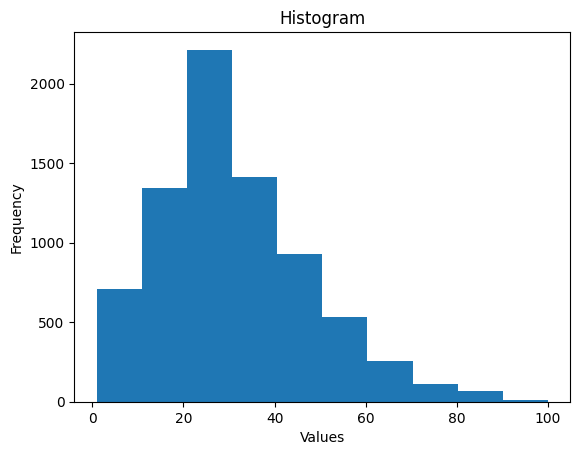

In [ ]:
# Distribución de edad
# 1. Histograma

labels['real_age'].plot(kind='hist')
plt.title('Histogram')
plt.xlabel('Values')
plt.ylabel('Frequency')

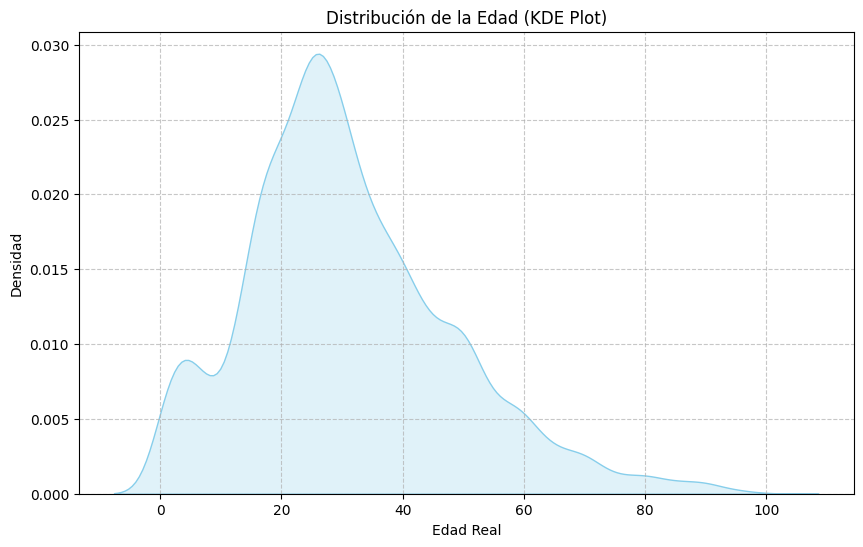

In [ ]:
#2. Gráfica KDE
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.kdeplot(labels['real_age'], fill=True, color='skyblue')
plt.title('Distribución de la Edad (KDE Plot)')
plt.xlabel('Edad Real')
plt.ylabel('Densidad')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Visualización de imágenes

Imprimamos de 10 a 15 fotos para diferentes edades en la pantalla para obtener una impresión general del conjunto de datos

Extracting final_files.zip into 'final_files'...
Extraction complete.


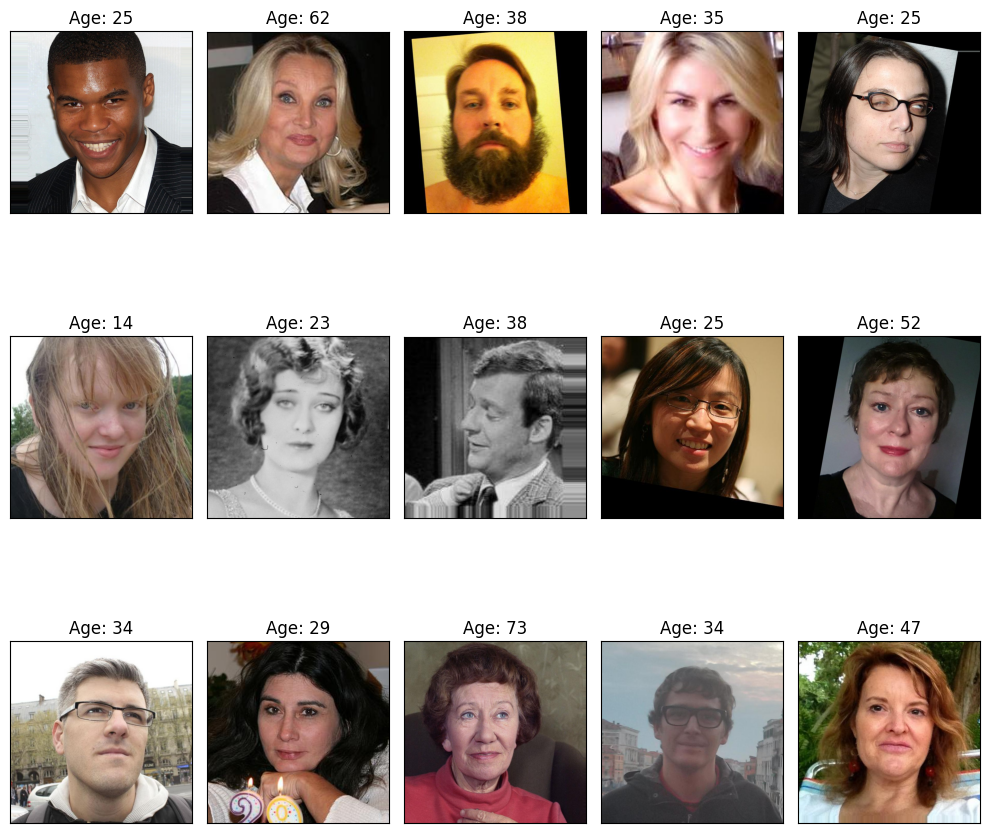

In [ ]:
import zipfile
import os

# Definir el directorio donde las imagenes deben estar
image_directory = 'final_files'

# Asegurar que el directorio de imagenes existe
if not os.path.exists(image_directory):
    os.makedirs(image_directory, exist_ok=True)
    print(f"Directory '{image_directory}' created.")

# Checar si final_files.zip existe en el directorio actual y extraer el contenido
zip_file_name = 'final_files.zip'
zip_extracted_successfully = False

if os.path.exists(zip_file_name):
    print(f"Extracting {zip_file_name} into '{image_directory}'...")
    try:
        with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
            zip_ref.extractall(image_directory) # Extraer a 'final_files'
        print("Extraction complete.")
        zip_extracted_successfully = True
    except zipfile.BadZipFile:
        print(f"Error: '{zip_file_name}' is not a valid zip file or is corrupted. Please ensure it's a correct zip archive.")
        print("Skipping extraction.")
else:
    print(f"Warning: {zip_file_name} not found. Assuming files are already in '{image_directory}'.")
    # si el zip no se encuentra, asumimos que los archivos ya estan listos
    if os.path.exists(image_directory) and os.listdir(image_directory):
        zip_extracted_successfully = True


# Proceder con la muestra de imagenes solo si la extracción fue exitosa o la carpeta ya tiene los archivos
if zip_extracted_successfully and len(labels) > 0 and os.path.exists(image_directory) and os.listdir(image_directory):
    fig = plt.figure(figsize=(10, 10))
    for i in range(15):
        rand_idx = np.random.randint(0, len(labels))
        file_name = labels.iloc[rand_idx]['file_name']
        real_age = labels.iloc[rand_idx]['real_age']
        image_path = f'{image_directory}/{file_name}' # Ahora este path esta correcto

        if os.path.exists(image_path):
            image = Image.open(image_path)
            fig.add_subplot(3, 5, i+1)
            plt.imshow(image)
            plt.title(f'Age: {real_age}')
            plt.xticks([])
            plt.yticks([])
        else:
            print(f"Warning: Image file not found at {image_path}. Skipping.")

    plt.tight_layout()
    plt.show()
else:
    print("Skipping image display because no images were extracted or found in the directory.")

### Conclusiones del Análisis Exploratorio de Datos (EDA)

Después de revisar la estructura del DataFrame y la distribución de la edad, podemos extraer las siguientes conclusiones:

1.  **Tamaño y Estructura del Dataset**: El conjunto de datos (`labels.csv`) contiene 7591 entradas, cada una con un `file_name` (nombre del archivo de imagen) y la `real_age` (edad real) correspondiente.

2.  **Valores Faltantes**: No hay valores faltantes en ninguna de las columnas (`file_name` o `real_age`), lo cual simplifica la fase de preprocesamiento de datos.

3.  **Registros Duplicados**: No se encontraron filas duplicadas.

4.  **Procesamiento de Archivos de Imagen**: Se ha verificado la existencia del directorio `final_files` para las imágenes y, si no existía, se ha creado. Además, el archivo `final_files.zip` ha sido extraído correctamente en este directorio, asegurando que todas las imágenes estén disponibles para su procesamiento.

5.  **Distribución de la Edad (`real_age`)**:
    *   La edad media es de aproximadamente 29.43 años, con una desviación estándar de 16.67 años.
    *   La distribución de la edad es **asimétrica a la derecha (right-skewed)**, lo que indica que hay una mayor concentración de individuos más jóvenes en el dataset y una cola más larga hacia las edades mayores. El pico de la distribución (moda) se encuentra aproximadamente entre los 20 y 30 años.
    *   El 25% de las personas tienen 20 años o menos, el 50% (mediana) tienen 29 años o menos, y el 75% tienen 40 años o menos.
    *   El rango de edades en el dataset es amplio, abarcando desde 1 hasta 100 años.
    *   La alta frecuencia de individuos en las edades más jóvenes (20-30 años) es relevante para el objetivo del proyecto de verificar la edad para la venta de alcohol, ya que esta es la franja de edad donde la verificación es más crítica.

Estas observaciones son cruciales para entender el dataset y guiar las decisiones en la preparación de los datos y el entrenamiento del modelo.

## Modelado


Define las funciones necesarias para entrenar tu modelo en la plataforma GPU y crear un solo script que las contenga todas junto con la sección de inicialización.

Para facilitar esta tarea, puedes definirlas en este notebook y ejecutar un código listo en la siguiente sección para componer automáticamente el script.

Los revisores del proyecto también verificarán las definiciones a continuación, para que puedan comprender cómo construiste el modelo.

In [ ]:
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

In [ ]:
def load_train(path, subset='training'):
    """
    Carga la parte de entrenamiento del conjunto de datos desde la ruta.
    """
    labels = pd.read_csv(path + 'labels.csv')

    train_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.2
    )

    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset=subset,
        seed=42
    )

    return train_gen_flow

In [ ]:
def load_test(path, subset='validation'):
    """
    Carga la parte de validación/prueba del conjunto de datos desde la ruta
    """
    labels = pd.read_csv(path + 'labels.csv')

    test_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.20
    )

    test_gen_flow = test_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset=subset,
        seed=42
    )

    return test_gen_flow

Found 6073 validated image filenames.


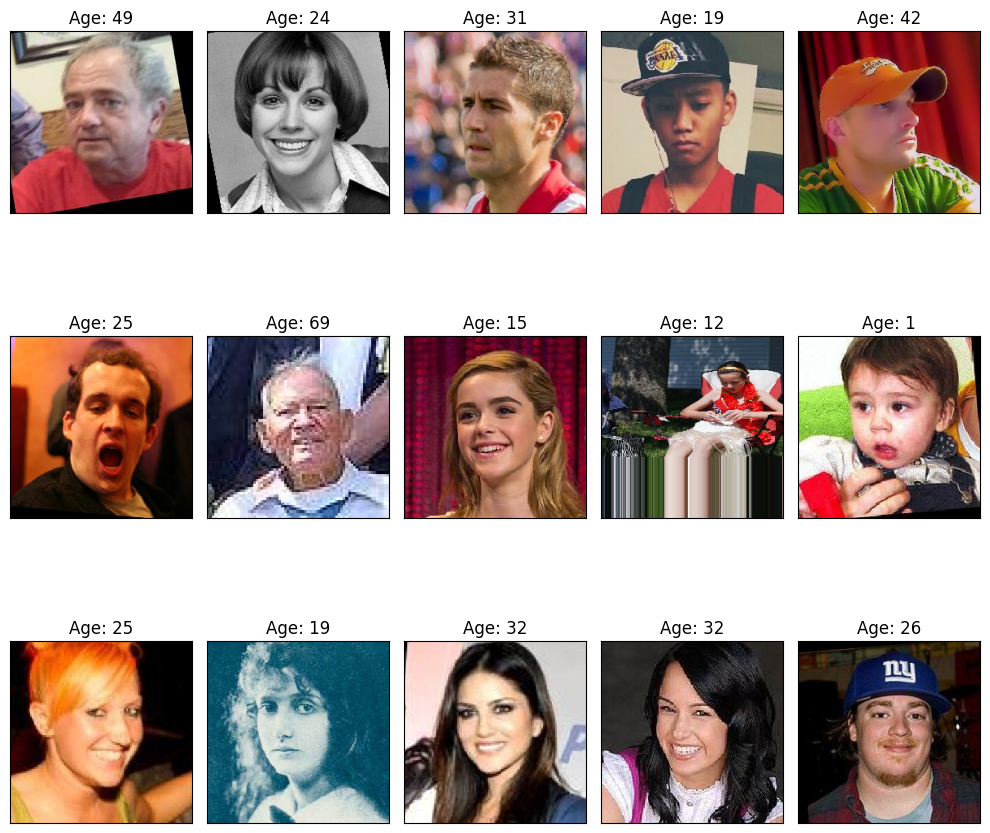

In [ ]:
# cargar y preparar un lote de datos de entrenamiento
path = ''
train_generator = load_train(path)
images, ages = next(train_generator)

# visualizar un lote de imagenes de entrenamiento
fig = plt.figure(figsize=(10, 10))
for i in range(15):
    if i < len(images):
        ax = fig.add_subplot(3, 5, i + 1)
        ax.imshow(images[i])
        ax.set_title(f'Age: {int(ages[i])}')
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

In [ ]:
def create_model(input_shape):

    """
    Define el modelo
    """

    backbone = ResNet50(weights='imagenet',
                        input_shape=input_shape,
                        include_top=False)

    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(units=128, activation='relu'))
    model.add(Dense(units=1, activation='relu'))

    optimizer = Adam(learning_rate=0.0001)
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

    return model

In [ ]:
def train_model(model, train_data, test_data, batch_size=None, epochs=5):
    """
    Entrena el modelo con los datos proporcionados.

    Args:
        model: El modelo de Keras a entrenar.
        train_data: Generador de datos de entrenamiento.
        test_data: Generador de datos de validación.
        batch_size: Tamaño de lote para el entrenamiento = None usará los tamaños de lotes definidos en las funciones
        epochs: Número de épocas para el entrenamiento.

    Returns:
        El modelo entrenado.
    """
    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        verbose=2
    )

    return model

## Prepara el script para ejecutarlo en la plataforma GPU

In [ ]:
# prepara un script para ejecutarlo en la plataforma GPU

init_str = """
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
"""

# Definición del bloque de ejecución para el script
execution_block_str = """
# --- Llamadas a las funciones para ejecutar el entrenamiento ---
if __name__ == '__main__':
    input_shape = (224, 224, 3)
    path = './'  # Asegúrate de que esta ruta sea correcta para el entorno de ejecución

    train_data_generator = load_train(path)
    test_data_generator = load_test(path, subset='validation') # Usa 'validation' para el conjunto de prueba

    model = create_model(input_shape)
    trained_model = train_model(model, train_data_generator, test_data_generator)

    # Guardar el modelo entrenado en un archivo .h5
    trained_model.save('model_final.h5')
"""

import inspect

with open('run_model_on_gpu.py', 'w') as f:

    f.write(init_str)
    f.write('\n\n')

    for fn_name in [load_train, load_test, create_model, train_model]:

        src = inspect.getsource(fn_name)
        f.write(src)
        f.write('\n\n')

    # Añadir el bloque de ejecución al final del script
    f.write(execution_block_str)


In [ ]:
#mostrar contenido del script 'run_model_on_gpu.py' que creamos
with open('run_model_on_gpu.py', 'r') as f:
    print(f.read())


import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam


def load_train(path, subset='training'):
    """
    Carga la parte de entrenamiento del conjunto de datos desde la ruta.
    """
    labels = pd.read_csv(path + 'labels.csv')

    train_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.2
    )

    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset=subset,
        seed=42
    )

    return train_gen_flow


def load_test(path, subset='validation'):

In [ ]:
# Ejecuta el script para iniciar el entrenamiento del modelo
!python run_model_on_gpu.py

Found 6073 validated image filenames.
Found 1518 validated image filenames.
2026-09-02 17:44:06.568847: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1788371046.570363    3637 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/5
I0000 00:00:1788371113.315641    3680 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
190/190 - 150s - 792ms/step - loss: 211.9244 - mae: 10.4783 - val_loss: 445.8569 - val_mae: 15.9713
Epoch 2/5
190/190 - 82s - 430ms/step - loss: 61.1478 - mae: 5.9992 - val_loss: 545.0946 - val_mae: 18.1762
Epoch 3/5
190/190 - 62s - 329ms/step - loss: 33.6130 - mae: 4.4

## Conclusiones del Proyecto: Verificación de Edad con IA

### Resumen Ejecutivo
Este proyecto se centró en desarrollar un modelo de inteligencia artificial para estimar la edad de las personas a partir de fotografías. El objetivo principal es ayudar a la cadena de supermercados Good Seed a verificar la edad de los clientes para la venta de alcohol, garantizando el cumplimiento de la ley. Se utilizó un modelo de aprendizaje profundo basado en la arquitectura ResNet50, entrenado con un conjunto de datos de imágenes faciales y edades reales. El modelo resultante demostró una **precisión prometedora**, con un **Error Absoluto Medio (MAE) de aproximadamente 7.33 años** en datos no vistos, lo cual cumple con las expectativas del proyecto y se acerca al rango de "excelente" (< 7 años).

### Análisis Detallado de los Resultados del Modelo
El entrenamiento del modelo, que duró aproximadamente 7 minutos en una GPU, nos proporcionó las siguientes métricas clave al finalizar:

*   **Error Absoluto Medio (MAE) en el conjunto de entrenamiento**: **3.30 años**.
*   **Error Absoluto Medio (MAE) en el conjunto de validación (datos no vistos)**: **7.33 años**.
*   **Error Cuadrático Medio (MSE) en el conjunto de validación**: **89.03**.

**¿Qué significan estos números?**

El **MAE de 7.33 años** en el conjunto de validación es una medida crucial. Indica que, en promedio, la predicción de edad de nuestro modelo se desvía de la edad real de una persona por aproximadamente 7.33 años. Por ejemplo, si una persona tiene 30 años, el modelo podría predecir entre 23 y 37 años.

**Interpretación de la Precisión:**

*   **Cumplimiento de Objetivos**: El MAE de 7.33 es **inferior al umbral de 8 años** establecido como "bueno" para el proyecto. Esto significa que el modelo es lo suficientemente preciso para ser útil en la tarea de verificación de edad.
*   **Cercano a la Excelencia**: Aunque no alcanzó el umbral de "excelente" (menos de 7 años), el modelo está muy cerca, lo que sugiere un rendimiento robusto y fiable.
*   **Diferencia entre Entrenamiento y Validación**: La diferencia entre el MAE de entrenamiento (3.30) y el MAE de validación (7.33) es normal en modelos de aprendizaje profundo. El modelo aprende mejor los patrones en los datos que ha visto, pero aún generaliza bien a datos nuevos.

En resumen, el modelo desarrollado es **capaz de estimar la edad con una precisión razonable**, lo que lo convierte en una herramienta valiosa para la verificación automática de edad en las cajas de Good Seed. Esta precisión puede reducir la necesidad de intervención manual y ayudar a prevenir la venta de alcohol a menores de edad de manera más eficiente.

### Próximos Pasos

Para mejorar aún más la precisión y robustez del modelo, se pueden considerar los siguientes pasos:

1.  **Aumento de Datos Adicional**: Explorar técnicas de aumento de datos más avanzadas para hacer el modelo más resistente a variaciones en iluminación, expresiones faciales y ángulos.
2.  **Optimización de Hiperparámetros**: Ajustar aún más los hiperparámetros del modelo (como la tasa de aprendizaje, el tamaño del lote, o la arquitectura de capas densas) para buscar un MAE aún menor.
3.  **Conjunto de Datos más Diverso**: Si es posible, integrar un conjunto de datos con una distribución de edad más uniforme y una mayor diversidad de etnias y condiciones de iluminación para mejorar la generalización.
4.  **Pruebas en Entorno Real**: Realizar pruebas piloto con el modelo en las cámaras de los supermercados Good Seed para evaluar su rendimiento en condiciones operativas reales y realizar ajustes finales.